# IAU – Fáza 3: Strojové učenie

## Autori
- Sofiia Berehovykh – 50 %
- Viktoriia Bondarets – 50 %

### Príprava dát

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate,
    GridSearchCV, learning_curve
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler, MinMaxScaler, PowerTransformer,
    QuantileTransformer, OneHotEncoder
)
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, ConfusionMatrixDisplay
)

if Path("data").is_dir():
    DATA_DIR = Path("data")
elif Path("../data").is_dir():
    DATA_DIR = Path("../data")
else:
    raise FileNotFoundError("Data folder not found")

units = pd.read_csv(DATA_DIR / "units.csv")
readings = pd.read_csv(DATA_DIR / "readings.csv", sep="\t")
readings = readings.drop_duplicates().reset_index(drop=True)

DUTY_MAP = {
    "1": "light", "l": "light", "light": "light",
    "2": "normal", "n": "normal", "normal": "normal", "med": "normal",
    "3": "heavy", "h": "heavy", "heavy": "heavy"
}


def prepare_data(readings, units, improved=False):
    r = readings.copy()
    u = units.copy()

    r["idUnit"] = pd.to_numeric(
        r["idUnit"].astype(str).str.extract(r"^U(\d+)$")[0], errors="coerce"
    )
    u["idUnit"] = pd.to_numeric(u["idUnit"], errors="coerce")
    r["tsCycle"] = pd.to_datetime(r["tsCycle"], format="mixed", errors="coerce")
    r["temperatureOil"] = r["temperatureOil"].replace(-999, np.nan)
    u["dutyClass"] = u["dutyClass"].apply(
        lambda x: x.strip().lower() if isinstance(x, str) else np.nan
    )

    if improved:
        u["dutyClass"] = u["dutyClass"].map(DUTY_MAP)
        r["currentMotor"] = r["currentMotor"].replace(99, np.nan)

    data = r.merge(u, on="idUnit", how="left")
    data.index = r.index

    data["cycle_month"] = data["tsCycle"].dt.month
    data["cycle_dayofweek"] = data["tsCycle"].dt.dayofweek
    data["cycle_hour"] = data["tsCycle"].dt.hour

    data = data.drop(
        columns=["idUnit", "tsCycle", "number_serial", "operatorOwner"],
        errors="ignore"
    )
    if improved:
        data = data.drop(columns=["idDepot"])

    for col in ["idDepot", "codeLine", "code_model", "dutyClass"]:
        if col in data.columns:
            data[col] = data[col].apply(lambda x: str(x) if pd.notna(x) else np.nan)

    return data


data = prepare_data(readings, units)
print("Dataset shape:", data.shape)
display(data.head())

Dataset shape: (14819, 18)


,currentMotor,dp_filter,temperatureOil,pressure_reservoir,pressure_oil,rms_vibration,Flowmeter,discharge_dewpoint,failure,year_commission,idDepot,codeLine,serviceHours,code_model,dutyClass,cycle_month,cycle_dayofweek,cycle_hour
0,4.52714,13.27287,38.37190,8.71234,3.20650,2.98947,26.46027,9.88857,0,2021.0,33.0,L6,11660.4,APU-15,l,1,1,0
1,4.29990,30.68875,62.89222,8.30207,3.50414,5.42665,30.37617,3.50537,0,2021.0,2.0,L5,13438.9,XC-7,light,3,3,0
2,2.67461,20.64984,44.05538,8.53038,3.31134,3.19845,15.69089,0.94667,0,2023.0,67.0,L3,6663.4,APU-20,1,1,0,0
3,4.06722,30.65835,76.27459,8.98351,3.88235,2.13170,24.62591,12.19307,1,2017.0,12.0,L4,24578.2,APU-15,1,11,0,0
4,7.30514,23.53441,57.95202,8.31182,3.18153,2.50357,21.52352,11.89736,0,2017.0,29.0,L1,26640.5,APU-20,h,12,5,22


Na začiatku sme načítali súbory `units.csv` a `readings.csv` a odstránili duplicitné záznamy. Všetky kroky čistenia z prvej a druhej fázy sme spojili do jednej funkcie `prepare_data()`. Atribút `cycle_year` sme oproti druhej fáze nevytvárali, pretože v časti 2.2 sme zistili, že je konštantný. Funkcia má parameter `improved`, pomocou ktorého neskôr zapneme ďalšie vylepšenia predspracovania.

In [2]:
X = data.drop(columns=["failure"])
y = data["failure"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Failure rate train/test:", round(y_train.mean(), 4), round(y_test.mean(), 4))

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
MAX_GAP = 0.05


def make_pipeline(model, X, scaler=None):
    if scaler is None:
        scaler = StandardScaler()
    num_cols = X.select_dtypes(include="number").columns.tolist()
    cat_cols = X.select_dtypes(exclude="number").columns.tolist()

    preprocessor = ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", scaler)
        ]), num_cols),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
        ]), cat_cols)
    ])
    return Pipeline([("preprocessing", preprocessor), ("model", model)])


def evaluate(y_true, y_pred, y_proba):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
        "roc_auc": roc_auc_score(y_true, y_proba)
    }


def evaluate_model(model, name, Xtr=None, ytr=None, Xte=None, yte=None):
    Xtr = X_train if Xtr is None else Xtr
    ytr = y_train if ytr is None else ytr
    Xte = X_test if Xte is None else Xte
    yte = y_test if yte is None else yte
    rows = []
    for split, Xd, yd in [("train", Xtr, ytr), ("test", Xte, yte)]:
        res = evaluate(yd, model.predict(Xd), model.predict_proba(Xd)[:, 1])
        res["model"] = name
        res["set"] = split
        rows.append(res)
    return pd.DataFrame(rows).set_index(["model", "set"]).round(4)


def cv_check(model, name, X=None, y=None):
    X = X_train if X is None else X
    y = y_train if y is None else y
    s = cross_validate(model, X, y, cv=CV, scoring=["roc_auc", "f1"],
                       return_train_score=True, n_jobs=-1)
    return {
        "model": name,
        "train_roc_auc": s["train_roc_auc"].mean(),
        "cv_roc_auc": s["test_roc_auc"].mean(),
        "cv_roc_auc_std": s["test_roc_auc"].std(),
        "cv_f1": s["test_f1"].mean(),
        "gap": s["train_roc_auc"].mean() - s["test_roc_auc"].mean()
    }


def pick_best(grid):
    res = pd.DataFrame(grid.cv_results_)
    res["gap"] = res["mean_train_score"] - res["mean_test_score"]
    ok = res[res["gap"] <= MAX_GAP]
    if ok.empty:
        ok = res.nsmallest(1, "gap")
    best = ok.sort_values("mean_test_score", ascending=False).iloc[0]
    return best["params"], res

Train: (11855, 17) Test: (2964, 17)
Failure rate train/test: 0.121 0.1211


Dáta sme rozdelili rovnako ako v druhej fáze: 80 % trénovacia a 20 % testovacia množina so stratifikáciou. Podiel záznamov s failure = 1 je v oboch množinách približne 12,1 %. Funkcia `make_pipeline()` vytvára rovnaké predspracovanie ako v časti 2.3 a pripája k nemu model. Funkcie `evaluate_model()` a `cv_check()` počítajú metriky na trénovacej a testovacej množine a pomocou 5-násobnej krížovej validácie. Ako hlavnú metriku sme zvolili ROC-AUC, pretože triedy sú nevyvážené. Za overfitting považujeme stav, keď je rozdiel medzi trénovacím a validačným ROC-AUC (`gap`) väčší ako 0,05. Funkcia `pick_best()` vyberá z výsledkov GridSearch najlepšiu kombináciu parametrov iba spomedzi modelov, ktoré túto podmienku spĺňajú.

## 3.1 Jednoduchý klasifikátor na základe závislosti v dátach
### A. Implementácia ID3 klasifikátora

In [3]:
id3_model = make_pipeline(
    DecisionTreeClassifier(criterion="entropy", max_depth=2,
                           class_weight="balanced", random_state=42),
    X_train
)
id3_model.fit(X_train, y_train)

id3_feature_names = list(id3_model.named_steps["preprocessing"].get_feature_names_out())
print("Tree depth:", id3_model.named_steps["model"].get_depth())
print("Number of leaves:", id3_model.named_steps["model"].get_n_leaves())
print()
print(export_text(id3_model.named_steps["model"], feature_names=id3_feature_names))

Tree depth: 2
Number of leaves: 4

|--- numeric__dp_filter <= -0.31
|   |--- numeric__serviceHours <= 0.49
|   |   |--- class: 0
|   |--- numeric__serviceHours >  0.49
|   |   |--- class: 1
|--- numeric__dp_filter >  -0.31
|   |--- numeric__dp_filter <= -0.24
|   |   |--- class: 1
|   |--- numeric__dp_filter >  -0.24
|   |   |--- class: 1



ID3 klasifikátor sme realizovali pomocou `DecisionTreeClassifier` s parametrom `criterion="entropy"`, ktorý vyberá atribúty na delenie podľa informačného zisku, rovnako ako algoritmus ID3. Rozdiel oproti klasickému ID3 je v tom, že scikit-learn vytvára vždy binárne delenia. Strom má hĺbku 2 a 4 listy. V koreni sa nachádza atribút `dp_filter`, na druhej úrovni `serviceHours` a opäť `dp_filter`. Hodnoty prahov sú po štandardizácii, napr. `dp_filter <= -0,31` znamená hodnotu mierne pod priemerom. Výsledok zodpovedá prvej fáze, kde sme zistili, že `dp_filter` má najsilnejší vzťah k premennej failure.

### B. Vyhodnotenie ID3 klasifikátora

accuracy  precision  recall      f1  roc_auc
model       set                                                
ID3 depth=2 train    0.4256     0.1547  0.8396  0.2613   0.6533
            test     0.4146     0.1479  0.8050  0.2499   0.6348

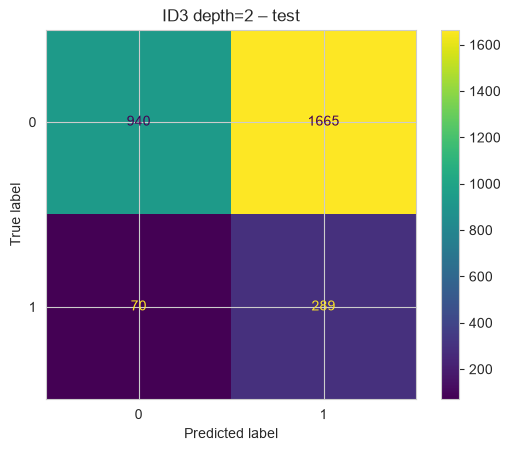

In [4]:
display(evaluate_model(id3_model, "ID3 depth=2"))

ConfusionMatrixDisplay.from_estimator(id3_model, X_test, y_test)
plt.title("ID3 depth=2 – test")
plt.show()

ID3 klasifikátor s hĺbkou 2 sme vyhodnotili na trénovacej aj testovacej množine. Na testovacej množine dosiahol ROC-AUC 0,635, recall 0,805, precision 0,148 a F1 0,250. Model teda zachytí približne 80 % porúch, ale za cenu veľkého počtu falošných poplachov. Matica zámen zobrazuje počty správne a nesprávne klasifikovaných záznamov: v riadkoch je skutočná hodnota failure, v stĺpcoch predikcia modelu. Hodnoty na trénovacej a testovacej množine sú veľmi podobné, takže model s hĺbkou 2 nemá overfitting.

### C. Overenie a riešenie overfittingu ID3 klasifikátora

,train_roc_auc,cv_roc_auc,gap,cv_f1
max_depth,,,,
2,0.6541,0.6459,0.0081,0.2593
3,0.7023,0.6855,0.0168,0.3082
4,0.7382,0.7003,0.0378,0.3060
5,0.7651,0.7032,0.0619,0.3126
6,0.7904,0.6990,0.0914,0.3172
7,0.8168,0.6867,0.1301,0.3136
8,0.8446,0.6762,0.1684,0.3165
9,0.8732,0.6547,0.2185,0.3076
10,0.8991,0.6369,0.2621,0.2919


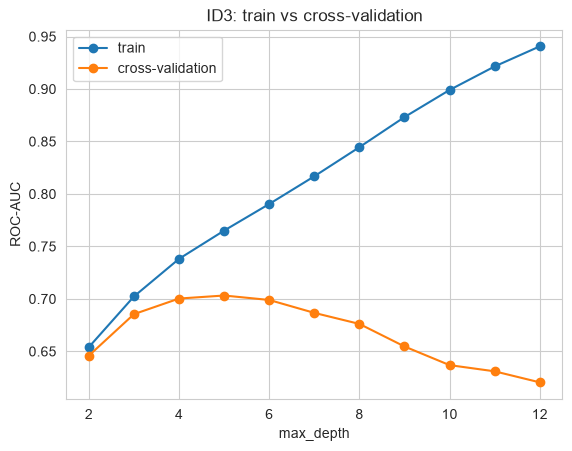

Unlimited ID3 depth: 37


accuracy  precision  recall      f1  roc_auc
model               set                                                
ID3 unlimited depth train    1.0000     1.0000  1.0000  1.0000   1.0000
                    test     0.8121     0.2525  0.2813  0.2661   0.5833

In [5]:
rows = []
for depth in range(2, 13):
    row = cv_check(
        make_pipeline(DecisionTreeClassifier(criterion="entropy", max_depth=depth,
                                             class_weight="balanced", random_state=42),
                      X_train),
        f"ID3 depth={depth}"
    )
    row["max_depth"] = depth
    rows.append(row)

id3_depths = pd.DataFrame(rows).set_index("max_depth")
display(id3_depths[["train_roc_auc", "cv_roc_auc", "gap", "cv_f1"]].round(4))

plt.plot(id3_depths.index, id3_depths["train_roc_auc"], marker="o", label="train")
plt.plot(id3_depths.index, id3_depths["cv_roc_auc"], marker="o", label="cross-validation")
plt.xlabel("max_depth")
plt.ylabel("ROC-AUC")
plt.title("ID3: train vs cross-validation")
plt.legend()
plt.show()

id3_deep = make_pipeline(
    DecisionTreeClassifier(criterion="entropy", max_depth=None,
                           class_weight="balanced", random_state=42),
    X_train
)
id3_deep.fit(X_train, y_train)
print("Unlimited ID3 depth:", id3_deep.named_steps["model"].get_depth())
display(evaluate_model(id3_deep, "ID3 unlimited depth"))

Na zistenie overfittingu sme trénovali ID3 klasifikátory s hĺbkou 2 až 12 a porovnali trénovacie ROC-AUC s ROC-AUC z 5-násobnej krížovej validácie. S rastúcou hĺbkou trénovacie skóre stále rastie, ale validačné skóre dosiahne maximum pri hĺbke 5 a potom klesá. Pre porovnanie sme natrénovali aj strom bez obmedzenia hĺbky, ktorý dosiahol hĺbku 37. Na trénovacej množine má všetky metriky rovné 1,0, ale na testovacej množine iba ROC-AUC 0,583 a F1 0,266. Takýto strom má výrazný overfitting.

In [6]:
id3_grid = GridSearchCV(
    make_pipeline(DecisionTreeClassifier(criterion="entropy", class_weight="balanced",
                                         random_state=42), X_train),
    param_grid={
        "model__max_depth": [2, 3, 4, 5, 6, 8],
        "model__min_samples_leaf": [1, 50, 100, 200]
    },
    scoring="roc_auc", cv=CV, return_train_score=True, n_jobs=-1
)
id3_grid.fit(X_train, y_train)

id3_params, id3_table = pick_best(id3_grid)
print("Best ID3 parameters:", id3_params)
display(id3_table[["params", "mean_train_score", "mean_test_score", "gap"]]
        .sort_values("mean_test_score", ascending=False).head(10).round(4))

id3_final = clone(id3_grid.estimator).set_params(**id3_params).fit(X_train, y_train)

display(pd.concat([
    evaluate_model(id3_deep, "ID3 unlimited (overfit)"),
    evaluate_model(id3_final, "ID3 tuned")
]))

Best ID3 parameters: {'model__max_depth': 5, 'model__min_samples_leaf': 100}


,params,mean_train_score,mean_test_score,gap
18,"{'model__max_depth': 6, 'model__min_samples_le...",0.7779,0.7140,0.0639
22,"{'model__max_depth': 8, 'model__min_samples_le...",0.8013,0.7136,0.0877
23,"{'model__max_depth': 8, 'model__min_samples_le...",0.7734,0.7110,0.0624
14,"{'model__max_depth': 5, 'model__min_samples_le...",0.7596,0.7108,0.0488
19,"{'model__max_depth': 6, 'model__min_samples_le...",0.7610,0.7073,0.0536
15,"{'model__max_depth': 5, 'model__min_samples_le...",0.7474,0.7062,0.0412
17,"{'model__max_depth': 6, 'model__min_samples_le...",0.7844,0.7047,0.0797
13,"{'model__max_depth': 5, 'model__min_samples_le...",0.7616,0.7047,0.0569
21,"{'model__max_depth': 8, 'model__min_samples_le...",0.8165,0.7034,0.1132
12,"{'model__max_depth': 5, 'model__min_samples_le...",0.7651,0.7032,0.0619


accuracy  precision  recall      f1  roc_auc
model                   set                                                
ID3 unlimited (overfit) train    1.0000     1.0000  1.0000  1.0000   1.0000
                        test     0.8121     0.2525  0.2813  0.2661   0.5833
ID3 tuned               train    0.6779     0.2281  0.6974  0.3438   0.7574
                        test     0.6619     0.2147  0.6741  0.3257   0.7066

Overfitting sme riešili obmedzením hĺbky stromu (`max_depth`) a minimálneho počtu záznamov v liste (`min_samples_leaf`). Pomocou GridSearchCV sme vyskúšali všetky kombinácie a vybrali najlepšiu iba spomedzi tých, kde je rozdiel medzi trénovacím a validačným ROC-AUC najviac 0,05. Najlepší ID3 má hĺbku 5 a minimálne 100 záznamov v liste. Upravený ID3 dosiahol na testovacej množine ROC-AUC 0,707 a F1 0,326, čo je výrazne lepšie ako strom bez obmedzenia (0,583) aj ako strom s hĺbkou 2 (0,635).

## 3.2 Trénovanie a vyhodnotenie klasifikátorov strojového učenia
### A, B. Stromový a nestromový algoritmus

In [7]:
dt_model = make_pipeline(
    DecisionTreeClassifier(max_depth=5, min_samples_leaf=50,
                           class_weight="balanced", random_state=42),
    X_train
)
dt_model.fit(X_train, y_train)

lr_model = make_pipeline(
    LogisticRegression(class_weight="balanced", max_iter=3000),
    X_train
)
lr_model.fit(X_train, y_train)

print("DecisionTree and LogisticRegression trained")

DecisionTree and LogisticRegression trained


Ako stromový algoritmus sme zvolili `DecisionTreeClassifier` (s hĺbkou 5 a minimálne 50 záznamami v liste) a ako nestromový algoritmus `LogisticRegression`. V oboch modeloch sme použili `class_weight="balanced"` kvôli nevyváženým triedam. Oba modely obsahujú rovnaké predspracovanie ako v druhej fáze, ktoré je spojené s modelom v jednom Pipeline.

### C, E. Porovnanie s ID3 a vyhodnotenie modelov

accuracy  precision  recall      f1  roc_auc
model              set                                                
ID3 tuned          train    0.6779     0.2281  0.6974  0.3438   0.7574
                   test     0.6619     0.2147  0.6741  0.3257   0.7066
DecisionTree       train    0.6720     0.2262  0.7071  0.3427   0.7591
                   test     0.6552     0.2115  0.6769  0.3223   0.7085
LogisticRegression train    0.6697     0.2186  0.6722  0.3299   0.7347
                   test     0.6515     0.2064  0.6602  0.3145   0.7068

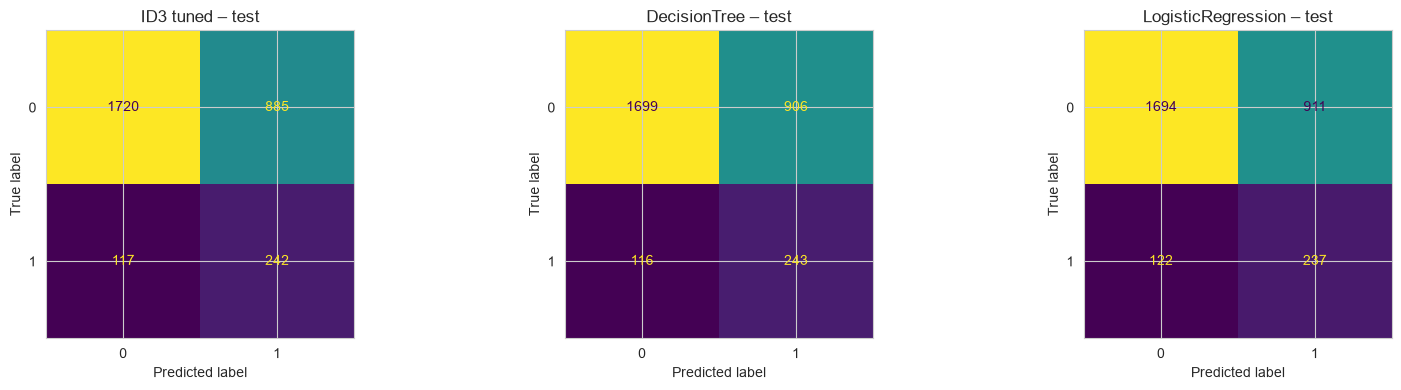

In [8]:
# 3.2 C, E – comparison with ID3 and evaluation with metrics
comparison = pd.concat([
    evaluate_model(id3_final, "ID3 tuned"),
    evaluate_model(dt_model, "DecisionTree"),
    evaluate_model(lr_model, "LogisticRegression")
])
display(comparison)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, model) in zip(axes, [("ID3 tuned", id3_final),
                                    ("DecisionTree", dt_model),
                                    ("LogisticRegression", lr_model)]):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=ax, colorbar=False)
    ax.set_title(f"{name} – test")
plt.tight_layout()
plt.show()

Všetky tri modely dosiahli na testovacej množine podobné výsledky: DecisionTree ROC-AUC 0,709 a F1 0,322, LogisticRegression ROC-AUC 0,707 a F1 0,315 a upravený ID3 ROC-AUC 0,707 a F1 0,326. Rozdiely medzi trénovacou a testovacou množinou sú malé, takže ani jeden model nemá výrazný overfitting. Všetky modely majú vysoký recall (približne 0,66 – 0,68), ale nízku precision (približne 0,21). Z matíc zámen vidíme, že modely zachytia väčšinu porúch, ale zároveň označia veľa záznamov bez poruchy ako poruchu.

### D. Vizualizácia natrénovaných pravidiel

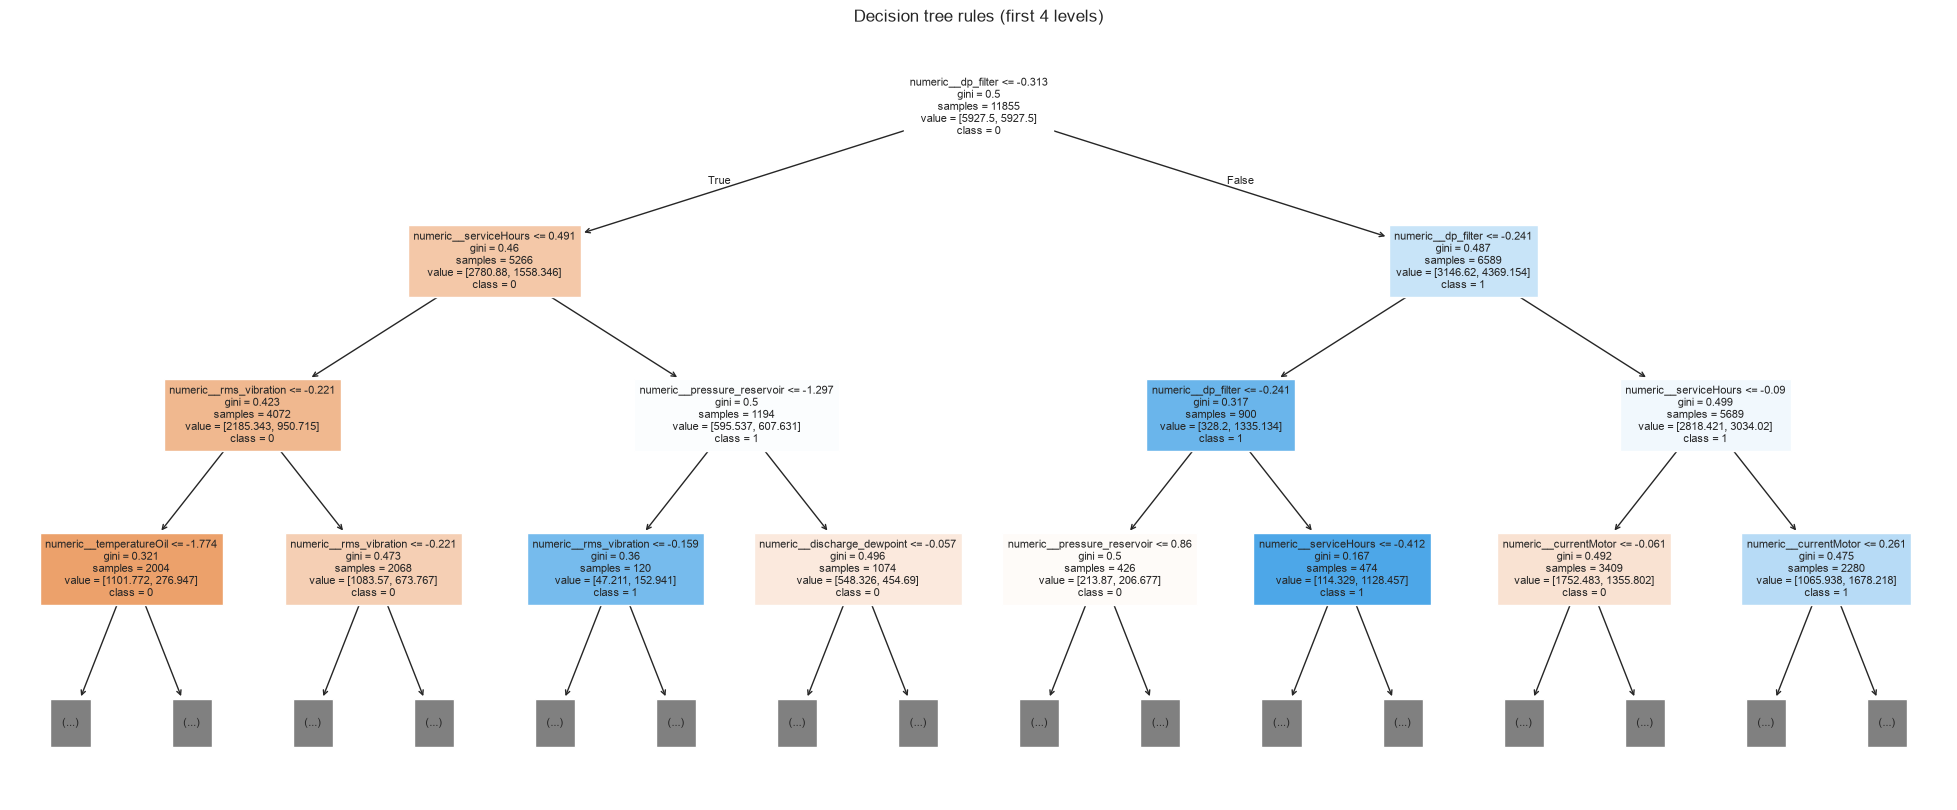

|--- numeric__dp_filter <= -0.31
|   |--- numeric__serviceHours <= 0.49
|   |   |--- numeric__rms_vibration <= -0.22
|   |   |   |--- numeric__temperatureOil <= -1.77
|   |   |   |   |--- class: 0
|   |   |   |--- numeric__temperatureOil >  -1.77
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- numeric__rms_vibration >  -0.22
|   |   |   |--- numeric__rms_vibration <= -0.22
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- numeric__rms_vibration >  -0.22
|   |   |   |   |--- truncated branch of depth 2
|   |--- numeric__serviceHours >  0.49
|   |   |--- numeric__pressure_reservoir <= -1.30
|   |   |   |--- numeric__rms_vibration <= -0.16
|   |   |   |   |--- class: 1
|   |   |   |--- numeric__rms_vibration >  -0.16
|   |   |   |   |--- class: 1
|   |   |--- numeric__pressure_reservoir >  -1.30
|   |   |   |--- numeric__discharge_dewpoint <= -0.06
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- numeric__discharge_dewpoint >  -0.06
|   |   |

In [9]:
feature_names = list(dt_model.named_steps["preprocessing"].get_feature_names_out())

plt.figure(figsize=(25, 10))
plot_tree(dt_model.named_steps["model"], max_depth=3, feature_names=feature_names,
          class_names=["0", "1"], filled=True, fontsize=8)
plt.title("Decision tree rules (first 4 levels)")
plt.show()

print(export_text(dt_model.named_steps["model"], feature_names=feature_names, max_depth=3))

 V koreni stromu je atribút `dp_filter` a na ďalších úrovniach sa nachádzajú najmä `serviceHours`, `rms_vibration`, `pressure_reservoir` a `currentMotor`. Vyššia hodnota `dp_filter` a vyšší počet prevádzkových hodín vedú k vyššiemu podielu porúch. Tieto atribúty zodpovedajú najdôležitejším atribútom, ktoré sme identifikovali v časti 2.2, a podporujú aj hypotézy z prvej fázy (`dp_filter`, `rms_vibration`).

## 3.3 Optimalizácia – hyperparameter tuning
### A. Nastavenie hyperparametrov

In [10]:
dt_grid = GridSearchCV(
    make_pipeline(DecisionTreeClassifier(class_weight="balanced", random_state=42), X_train),
    param_grid={
        "model__max_depth": [3, 4, 5, 6, 8, 10],
        "model__min_samples_leaf": [20, 50, 100, 200],
        "model__criterion": ["gini", "entropy"]
    },
    scoring="roc_auc", cv=CV, return_train_score=True, n_jobs=-1
)
dt_grid.fit(X_train, y_train)

dt_params, dt_table = pick_best(dt_grid)
print("Best DecisionTree parameters:", dt_params)
display(dt_table[["params", "mean_train_score", "mean_test_score", "gap"]]
        .sort_values("mean_test_score", ascending=False).head(10).round(4))

dt_tuned = clone(dt_grid.estimator).set_params(**dt_params).fit(X_train, y_train)

Best DecisionTree parameters: {'model__criterion': 'gini', 'model__max_depth': 5, 'model__min_samples_leaf': 100}


,params,mean_train_score,mean_test_score,gap
10,"{'model__criterion': 'gini', 'model__max_depth...",0.7636,0.7161,0.0475
18,"{'model__criterion': 'gini', 'model__max_depth...",0.8049,0.7160,0.0889
22,"{'model__criterion': 'gini', 'model__max_depth...",0.8144,0.7156,0.0987
14,"{'model__criterion': 'gini', 'model__max_depth...",0.7828,0.7151,0.0677
15,"{'model__criterion': 'gini', 'model__max_depth...",0.7646,0.7141,0.0504
38,"{'model__criterion': 'entropy', 'model__max_de...",0.7779,0.7140,0.0639
42,"{'model__criterion': 'entropy', 'model__max_de...",0.8013,0.7136,0.0877
23,"{'model__criterion': 'gini', 'model__max_depth...",0.7753,0.7128,0.0625
19,"{'model__criterion': 'gini', 'model__max_depth...",0.7750,0.7128,0.0622
47,"{'model__criterion': 'entropy', 'model__max_de...",0.7752,0.7123,0.0629


Hyperparametre pre `DecisionTreeClassifier` sme hľadali pomocou GridSearchCV s 5-násobnou krížovou validáciou. Vyskúšali sme hĺbku stromu (3 – 10), minimálny počet záznamov v liste (20 – 200) a kritérium (gini, entropy), spolu 48 kombinácií. Najlepšia kombinácia bez overfittingu je kritérium gini, hĺbka 5 a minimálne 100 záznamov v liste.

### B. Kombinácie modelov (ensemble)

In [11]:
rf_grid = GridSearchCV(
    make_pipeline(RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                         random_state=42), X_train),
    param_grid={
        "model__max_depth": [4, 6, 8],
        "model__min_samples_leaf": [20, 50]
    },
    scoring="roc_auc", cv=CV, return_train_score=True, n_jobs=-1
)
rf_grid.fit(X_train, y_train)
rf_params, rf_table = pick_best(rf_grid)
print("Best RandomForest parameters:", rf_params)
rf_tuned = clone(rf_grid.estimator).set_params(**rf_params).fit(X_train, y_train)

hgb_grid = GridSearchCV(
    make_pipeline(HistGradientBoostingClassifier(class_weight="balanced",
                                                 min_samples_leaf=50,
                                                 random_state=42), X_train),
    param_grid={
        "model__learning_rate": [0.05, 0.1],
        "model__max_depth": [2, 3],
        "model__max_iter": [100, 200, 300]
    },
    scoring="roc_auc", cv=CV, return_train_score=True, n_jobs=-1
)
hgb_grid.fit(X_train, y_train)
hgb_params, hgb_table = pick_best(hgb_grid)
print("Best HistGradientBoosting parameters:", hgb_params)
display(hgb_table[["params", "mean_train_score", "mean_test_score", "gap"]]
        .sort_values("mean_test_score", ascending=False).head(10).round(4))
hgb_tuned = clone(hgb_grid.estimator).set_params(**hgb_params).fit(X_train, y_train)

Best RandomForest parameters: {'model__max_depth': 4, 'model__min_samples_leaf': 20}
Best HistGradientBoosting parameters: {'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__max_iter': 200}


,params,mean_train_score,mean_test_score,gap
8,"{'model__learning_rate': 0.1, 'model__max_dept...",0.8650,0.7926,0.0723
7,"{'model__learning_rate': 0.1, 'model__max_dept...",0.8526,0.7912,0.0614
5,"{'model__learning_rate': 0.05, 'model__max_dep...",0.8796,0.7897,0.0899
2,"{'model__learning_rate': 0.05, 'model__max_dep...",0.8451,0.7892,0.0559
4,"{'model__learning_rate': 0.05, 'model__max_dep...",0.8659,0.7886,0.0773
10,"{'model__learning_rate': 0.1, 'model__max_dept...",0.8904,0.7879,0.1025
9,"{'model__learning_rate': 0.1, 'model__max_dept...",0.8657,0.7872,0.0785
11,"{'model__learning_rate': 0.1, 'model__max_dept...",0.9107,0.7868,0.1239
1,"{'model__learning_rate': 0.05, 'model__max_dep...",0.8339,0.7856,0.0484
6,"{'model__learning_rate': 0.1, 'model__max_dept...",0.8335,0.7853,0.0482


Vyskúšali sme dva ensemble modely, ktoré sú zložené z viacerých rozhodovacích stromov. `RandomForestClassifier` vytvorí 200 stromov, pričom každý sa učí na inej náhodne vybranej časti trénovacích dát. Výsledná predikcia sa určí podľa toho, ako rozhodla väčšina stromov. `HistGradientBoostingClassifier` vytvára stromy postupne, pričom každý ďalší strom opravuje chyby predchádzajúcich. Pre oba modely sme opäť použili GridSearchCV a podmienku rozdielu najviac 0,05. Najlepší Random Forest má hĺbku 4 a minimálne 20 záznamov v liste. Najlepší HistGradientBoosting má learning rate 0,05, hĺbku 2 a 200 iterácií.

### C. Krížová validácia na trénovacej množine

,train_roc_auc,cv_roc_auc,cv_roc_auc_std,cv_f1,gap,overfit
model,,,,,,
HistGradientBoosting tuned,0.8339,0.7856,0.0057,0.3913,0.0484,False
RandomForest tuned,0.7721,0.7307,0.0143,0.3336,0.0414,False
DecisionTree tuned,0.7636,0.7161,0.0058,0.3297,0.0475,False
DecisionTree (default),0.7655,0.7112,0.0086,0.3255,0.0543,True
ID3 tuned,0.7596,0.7108,0.0063,0.3196,0.0488,False
LogisticRegression,0.7398,0.6934,0.0170,0.3061,0.0464,False


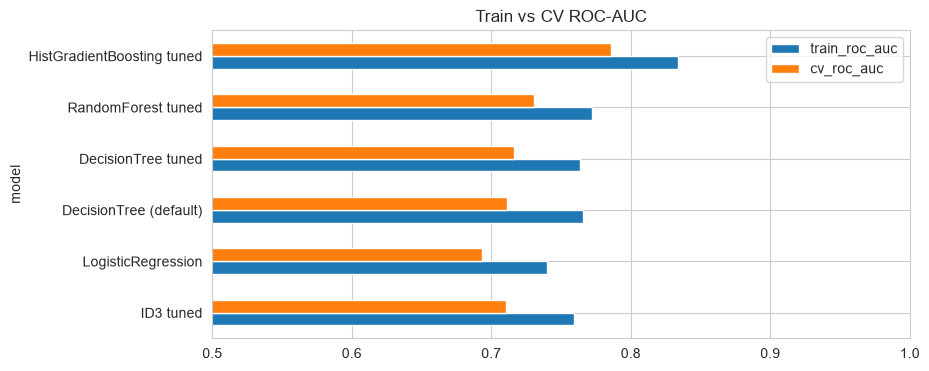

In [12]:

summary = pd.DataFrame([
    cv_check(id3_final, "ID3 tuned"),
    cv_check(lr_model, "LogisticRegression"),
    cv_check(dt_model, "DecisionTree (default)"),
    cv_check(dt_tuned, "DecisionTree tuned"),
    cv_check(rf_tuned, "RandomForest tuned"),
    cv_check(hgb_tuned, "HistGradientBoosting tuned")
]).set_index("model")
summary["overfit"] = summary["gap"] > MAX_GAP
display(summary.sort_values("cv_roc_auc", ascending=False).round(4))

summary[["train_roc_auc", "cv_roc_auc"]].plot.barh(figsize=(9, 4))
plt.xlim(0.5, 1)
plt.title("Train vs CV ROC-AUC")
plt.show()

Všetky modely sme porovnali pomocou 5-násobnej krížovej validácie na trénovacej množine. Trénovacia množina sa rozdelí na 5 častí, model sa 5-krát natrénuje na 4 častiach a vyhodnotí na zvyšnej. Najlepšie výsledky dosiahol HistGradientBoosting (ROC-AUC 0,786, F1 0,391), nasleduje Random Forest (0,731), upravený DecisionTree (0,716), DecisionTree s pôvodnými parametrami (0,711), upravený ID3 (0,711) a LogisticRegression (0,693). Overfitting mal iba DecisionTree s pôvodnými parametrami (0,054). Ensemble model HistGradientBoosting zlepšil ROC-AUC oproti jednému stromu približne o 0,07.

### D. Overenie, že najlepší model nemá overfitting

Best model without overfitting: HistGradientBoosting tuned


accuracy  precision  recall      f1  roc_auc
model                      set                                                
HistGradientBoosting tuned train    0.7638     0.3024  0.7287  0.4274   0.8276
                           test     0.7490     0.2820  0.6936  0.4010   0.7853

,train_roc_auc,cv_roc_auc,cv_roc_auc_std,cv_f1,gap,overfit
model,,,,,,
HistGradientBoosting tuned,0.8339,0.7856,0.0057,0.3913,0.0484,False


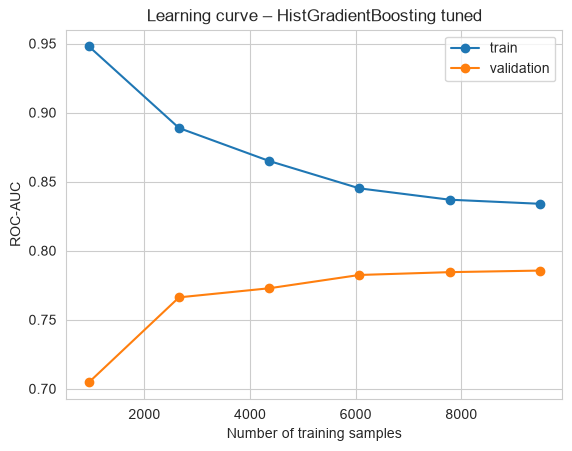

In [13]:
models = {
    "ID3 tuned": id3_final,
    "LogisticRegression": lr_model,
    "DecisionTree (default)": dt_model,
    "DecisionTree tuned": dt_tuned,
    "RandomForest tuned": rf_tuned,
    "HistGradientBoosting tuned": hgb_tuned
}
best_name = summary[~summary["overfit"]]["cv_roc_auc"].idxmax()
best_model = models[best_name]
print("Best model without overfitting:", best_name)

display(evaluate_model(best_model, best_name))
display(summary.loc[[best_name]].round(4))

sizes, train_scores, val_scores = learning_curve(
    clone(best_model), X_train, y_train, cv=CV, scoring="roc_auc",
    train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1
)
plt.plot(sizes, train_scores.mean(axis=1), marker="o", label="train")
plt.plot(sizes, val_scores.mean(axis=1), marker="o", label="validation")
plt.xlabel("Number of training samples")
plt.ylabel("ROC-AUC")
plt.title(f"Learning curve – {best_name}")
plt.legend()
plt.show()

Ako najlepší model bez overfittingu sme vybrali HistGradientBoosting. Že nemá overfitting, dokazujeme troma spôsobmi:
1. Trénovacie ROC-AUC (0,834), validačné ROC-AUC (0,786) a testovacie ROC-AUC (0,785) sú blízko seba a rozdiel je menší ako 0,05. Testovacie skóre je takmer rovnaké ako validačné, takže krížová validácia správne odhadla výkonnosť na nových dátach.
2. Štandardná odchýlka validačného ROC-AUC medzi jednotlivými časťami je iba 0,006, takže model je stabilný.
3. Na krivke učenia vidíme, ako sa s rastúcim počtom trénovacích záznamov mení trénovacie a validačné skóre a že sa rozdiel medzi nimi neprehlbuje.
Zároveň model nemá underfitting, pretože dosahuje výrazne lepšie výsledky ako jednoduchšie modely.

## 3.4 Vyhodnotenie vplyvu zvolenej stratégie riešenia na klasifikáciu
### A. Stratégie riešenia v predspracovaní dát

In [14]:
display(X_train.assign(failure=y_train)
        .groupby("dutyClass")["failure"].agg(["count", "mean"])
        .assign(real_class=lambda d: d.index.map(DUTY_MAP)).round(4))

data2 = prepare_data(readings, units, improved=True)
X2 = data2.drop(columns=["failure"])
X2_train = X2.loc[X_train.index]
X2_test = X2.loc[X_test.index]

best_estimator = clone(best_model.named_steps["model"])

prep_comparison = pd.DataFrame([
    cv_check(make_pipeline(clone(best_estimator), X_train),
             "phase 2 preprocessing", X_train, y_train),
    cv_check(make_pipeline(clone(best_estimator), X2_train),
             "improved preprocessing", X2_train, y_train)
]).set_index("model")
display(prep_comparison.round(4))

,count,mean,real_class
dutyClass,,,
1,1639,0.1702,light
2,892,0.1043,normal
3,907,0.0695,heavy
h,977,0.0491,heavy
heavy,1151,0.0634,heavy
l,1468,0.1901,light
light,1593,0.1707,light
med,1011,0.1128,normal
n,1134,0.0988,normal


,train_roc_auc,cv_roc_auc,cv_roc_auc_std,cv_f1,gap
model,,,,,
phase 2 preprocessing,0.8339,0.7856,0.0057,0.3913,0.0484
improved preprocessing,0.8379,0.7967,0.0065,0.4033,0.0412


V tejto časti sme porovnali predspracovanie z druhej fázy s vylepšeným predspracovaním (`improved=True`), ktoré obsahuje tri zmeny:
1. Zjednotenie `dutyClass`: atribút obsahuje 10 rôznych zápisov, ktoré v skutočnosti predstavujú iba 3 triedy (1/l/light, 2/n/med/normal, 3/h/heavy). Tabuľka ukazuje, že zápisy jednej triedy majú takmer rovnaký podiel porúch (light približne 17 – 19 %, normal 9 – 11 %, heavy 5 – 7 %).
2. Nahradenie hodnoty 99 v `currentMotor` za NaN, pretože ide o podozrivú hodnotu identifikovanú už v prvej fáze (podobne ako -999 v `temperatureOil`).
3. Odstránenie `idDepot`, ktorý má približne 120 hodnôt a po zakódovaní vytvára veľa riedkych atribútov.

Vylepšené predspracovanie zvýšilo validačné ROC-AUC z 0,786 na 0,797 a F1 z 0,391 na 0,403, pričom rozdiel medzi trénovacou a validačnou množinou sa zmenšil z 0,048 na 0,041. Stratégia predspracovania je teda pre náš dataset účinná.

### B. Dátová transformácia (scaling, transformer)

In [15]:
scalers = {
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "PowerTransformer": PowerTransformer(),
    "QuantileTransformer": QuantileTransformer(output_distribution="normal",
                                               random_state=42)
}

rows = []
for scaler_name, scaler in scalers.items():
    for model_name, model in [
        ("LogisticRegression", LogisticRegression(class_weight="balanced", max_iter=3000)),
        (best_name, best_estimator)
    ]:
        row = cv_check(make_pipeline(clone(model), X2_train, clone(scaler)),
                       model_name, X2_train, y_train)
        row["scaler"] = scaler_name
        rows.append(row)

scaler_comparison = pd.DataFrame(rows).set_index(["model", "scaler"])
display(scaler_comparison.round(4))

,,train_roc_auc,cv_roc_auc,cv_roc_auc_std,cv_f1,gap
model,scaler,,,,,
LogisticRegression,StandardScaler,0.7380,0.7306,0.0136,0.3339,0.0074
HistGradientBoosting tuned,StandardScaler,0.8379,0.7967,0.0065,0.4033,0.0412
LogisticRegression,MinMaxScaler,0.7379,0.7306,0.0139,0.3338,0.0073
HistGradientBoosting tuned,MinMaxScaler,0.8379,0.7967,0.0065,0.4033,0.0412
LogisticRegression,PowerTransformer,0.7450,0.7370,0.0100,0.3356,0.0080
HistGradientBoosting tuned,PowerTransformer,0.8379,0.7967,0.0065,0.4033,0.0412
LogisticRegression,QuantileTransformer,0.7438,0.7361,0.0113,0.3369,0.0077
HistGradientBoosting tuned,QuantileTransformer,0.8379,0.7967,0.0065,0.4033,0.0412


Vplyv transformácií sme overili na štyroch technikách z druhej fázy. Pre LogisticRegression a pre najlepší model. Pri LogisticRegression majú transformácie vplyv: PowerTransformer dosiahol najlepšie ROC-AUC (0,737), nasleduje QuantileTransformer (0,736), kým StandardScaler a MinMaxScaler dosiahli 0,731. Transformery znižujú asymetriu rozdelení a vplyv odľahlých hodnôt, čo lineárnemu modelu pomáha. Pri HistGradientBoosting sú výsledky pri všetkých transformáciách úplne rovnaké (0,797), pretože stromové modely iba porovnávajú hodnotu s prahom a poradie hodnôt sa transformáciou nemení. Pre finálny model preto voľba transformácie nemá význam a ponechali sme StandardScaler.

### C. Výber atribútov, metrík, algoritmov, hyperparametrov a ensemble learning

,model,train_roc_auc,cv_roc_auc,cv_roc_auc_std,cv_f1,gap
k,,,,,,
3,top 3,0.7754,0.7488,0.0209,0.3521,0.0267
5,top 5,0.8026,0.7775,0.0101,0.3804,0.0251
7,top 7,0.8184,0.7828,0.0045,0.3908,0.0356
9,top 9,0.8327,0.7956,0.0071,0.4081,0.0371
11,top 11,0.8377,0.7968,0.0066,0.4011,0.0409
13,top 13,0.8379,0.7971,0.0071,0.4021,0.0408
16,top 16,0.8379,0.7967,0.0065,0.4033,0.0412


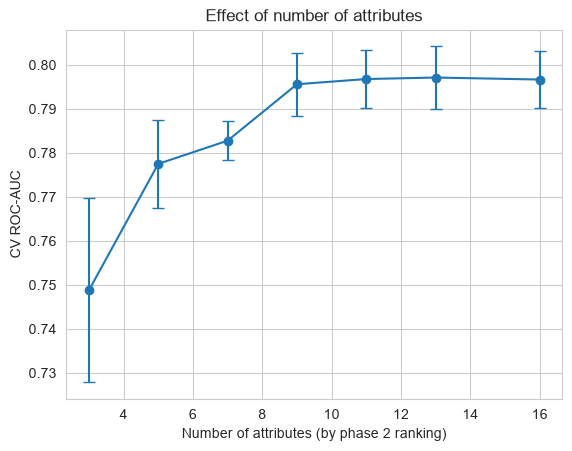

Best number of attributes: 13
Final features: ['dp_filter', 'serviceHours', 'rms_vibration', 'year_commission', 'dutyClass', 'pressure_reservoir', 'discharge_dewpoint', 'pressure_oil', 'currentMotor', 'temperatureOil', 'Flowmeter', 'cycle_month', 'cycle_dayofweek']
Summary of algorithms, tuning and ensembles:


,train_roc_auc,cv_roc_auc,cv_roc_auc_std,cv_f1,gap,overfit
model,,,,,,
HistGradientBoosting tuned,0.8339,0.7856,0.0057,0.3913,0.0484,False
RandomForest tuned,0.7721,0.7307,0.0143,0.3336,0.0414,False
DecisionTree tuned,0.7636,0.7161,0.0058,0.3297,0.0475,False
DecisionTree (default),0.7655,0.7112,0.0086,0.3255,0.0543,True
ID3 tuned,0.7596,0.7108,0.0063,0.3196,0.0488,False
LogisticRegression,0.7398,0.6934,0.0170,0.3061,0.0464,False


In [16]:
feature_ranking = [
    "dp_filter", "serviceHours", "rms_vibration", "year_commission",
    "dutyClass", "pressure_reservoir", "discharge_dewpoint", "pressure_oil",
    "currentMotor", "temperatureOil", "Flowmeter", "cycle_month",
    "cycle_dayofweek", "code_model", "codeLine", "cycle_hour"
]

rows = []
for k in [3, 5, 7, 9, 11, 13, len(feature_ranking)]:
    features_k = feature_ranking[:k]
    row = cv_check(
        make_pipeline(clone(best_estimator), X2_train[features_k]),
        f"top {k}", X2_train[features_k], y_train
    )
    row["k"] = k
    rows.append(row)

feature_comparison = pd.DataFrame(rows).set_index("k")
display(feature_comparison.round(4))

plt.errorbar(feature_comparison.index, feature_comparison["cv_roc_auc"],
             yerr=feature_comparison["cv_roc_auc_std"], marker="o", capsize=4)
plt.xlabel("Number of attributes (by phase 2 ranking)")
plt.ylabel("CV ROC-AUC")
plt.title("Effect of number of attributes")
plt.show()

best_k = feature_comparison["cv_roc_auc"].idxmax()
final_features = feature_ranking[:best_k]
print("Best number of attributes:", best_k)
print("Final features:", final_features)

print("Summary of algorithms, tuning and ensembles:")
display(summary.sort_values("cv_roc_auc", ascending=False).round(4))

Na výber atribútov sme použili poradie dôležitosti atribútov z časti 2.2 a krížovou validáciou overili, koľko atribútov je vhodné použiť (3, 5, 7, 9, 11, 13 a všetkých 16). Najlepší výsledok dosiahlo 13 atribútov, rozdiely od 9 atribútov sú však menšie ako štandardná odchýlka (približne 0,007). Atribúty `codeLine`, `code_model` a `cycle_hour` výsledok nezlepšujú.
Súhrnná tabuľka ukazuje vplyv ďalších rozhodnutí:
- **Metriky:** ROC-AUC a F1 sú vhodnejšie ako accuracy, pretože triedy sú nevyvážené.
- **Algoritmy:** stromové ensemble modely sú lepšie ako jeden strom a LogisticRegression.
- **Hyperparameter tuning:** pri DecisionTree zvýšil ROC-AUC z 0,711 na 0,716 a odstránil overfitting.
- **Ensemble learning:** priniesol najväčšie zlepšenie (HistGradientBoosting 0,786 oproti 0,716 pri jednom strome).

### D. Najlepší model pre nasadenie

accuracy  precision  recall      f1  roc_auc
model       set                                                
FINAL MODEL train    0.7703     0.3105  0.7364  0.4368   0.8326
            test     0.7554     0.2939  0.7270  0.4186   0.8009

,model,train_roc_auc,cv_roc_auc,cv_roc_auc_std,cv_f1,gap
0,FINAL MODEL (CV),0.8379,0.7971,0.0071,0.4021,0.0408


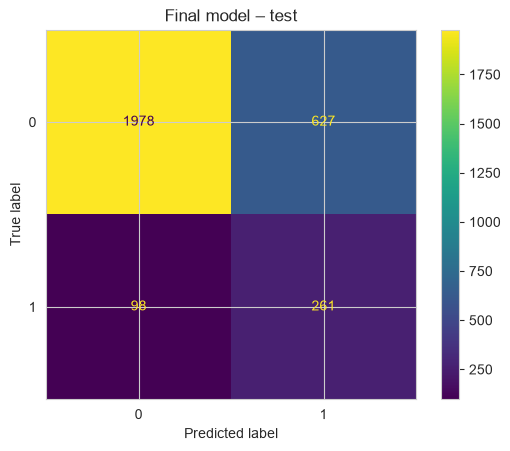

In [17]:
final_model = make_pipeline(clone(best_estimator), X2_train[final_features])
final_model.fit(X2_train[final_features], y_train)

display(evaluate_model(final_model, "FINAL MODEL",
                       X2_train[final_features], y_train,
                       X2_test[final_features], y_test))
display(pd.DataFrame([cv_check(final_model, "FINAL MODEL (CV)",
                               X2_train[final_features], y_train)]).round(4))

ConfusionMatrixDisplay.from_estimator(final_model, X2_test[final_features], y_test)
plt.title("Final model – test")
plt.show()

Ako najlepší model pre nasadenie sme zvolili HistGradientBoosting (learning rate 0,05, hĺbka 2, 200 iterácií) s vylepšeným predspracovaním a 13 atribútmi. Model sme natrénovali na celej trénovacej množine a jedenkrát vyhodnotili na testovacej množine, ktorú sme dovtedy nepoužili na žiadne rozhodnutia. Na testovacej množine dosiahol ROC-AUC 0,801, F1 0,419, recall 0,727, precision 0,294 a accuracy 0,755. Trénovacie ROC-AUC je 0,833, validačné 0,797 a testovacie 0,801 – hodnoty sú blízko seba, takže model nemá overfitting ani underfitting a je stabilný.

### E. Data pipeline pre produkciu

In [18]:
MODEL_DIR = Path("faza3_model")
MODEL_DIR.mkdir(exist_ok=True)

joblib.dump(final_model, MODEL_DIR / "final_model.joblib")
units.to_csv(MODEL_DIR / "units_lookup.csv", index=False)

test_metrics = evaluate(
    y_test,
    final_model.predict(X2_test[final_features]),
    final_model.predict_proba(X2_test[final_features])[:, 1]
)

metadata = {
    "algorithm": best_name,
    "model_params": {k: str(v) for k, v in best_estimator.get_params().items()},
    "features": final_features,
    "duty_class_map": DUTY_MAP,
    "invalid_values_to_nan": {"temperatureOil": -999, "currentMotor": 99},
    "dropped_columns": ["idDepot", "number_serial", "operatorOwner"],
    "missing_values": "numeric = median, categorical = most frequent (fitted on train)",
    "train_rows": len(X2_train),
    "test_metrics": {k: round(float(v), 4) for k, v in test_metrics.items()},
    "created": pd.Timestamp.now().isoformat()
}
with open(MODEL_DIR / "metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)
print(json.dumps(metadata, indent=2))


def predict_failure(new_readings):
    model = joblib.load(MODEL_DIR / "final_model.joblib")
    units_lookup = pd.read_csv(MODEL_DIR / "units_lookup.csv")
    with open(MODEL_DIR / "metadata.json") as f:
        meta = json.load(f)

    X_new = prepare_data(new_readings, units_lookup, improved=True)[meta["features"]]

    result = new_readings[["idUnit", "tsCycle"]].copy()
    result["failure_probability"] = model.predict_proba(X_new)[:, 1].round(3)
    result["predicted_failure"] = model.predict(X_new)
    return result


new_readings = readings.loc[X_test.index].drop(columns=["failure"]).head(10)
display(predict_failure(new_readings))

{
  "algorithm": "HistGradientBoosting tuned",
  "model_params": {
    "categorical_features": "from_dtype",
    "class_weight": "balanced",
    "early_stopping": "auto",
    "interaction_cst": "None",
    "l2_regularization": "0.0",
    "learning_rate": "0.05",
    "loss": "log_loss",
    "max_bins": "255",
    "max_depth": "2",
    "max_features": "1.0",
    "max_iter": "200",
    "max_leaf_nodes": "31",
    "min_samples_leaf": "50",
    "monotonic_cst": "None",
    "n_iter_no_change": "10",
    "random_state": "42",
    "scoring": "loss",
    "tol": "1e-07",
    "validation_fraction": "0.1",
    "verbose": "0",
    "warm_start": "False"
  },
  "features": [
    "dp_filter",
    "serviceHours",
    "rms_vibration",
    "year_commission",
    "dutyClass",
    "pressure_reservoir",
    "discharge_dewpoint",
    "pressure_oil",
    "currentMotor",
    "temperatureOil",
    "Flowmeter",
    "cycle_month",
    "cycle_dayofweek"
  ],
  "duty_class_map": {
    "1": "light",
    "l": "light"

,idUnit,tsCycle,failure_probability,predicted_failure
6139,U00296,25 Aug 2023,0.412,0
7520,U01234,"08/23/2023, 17:14:00",0.424,0
2314,U01401,2023-03-21,0.351,0
6205,U01816,22 Sep 2023,0.808,1
1810,U01159,2023-12-16,0.268,0
14506,U00780,2023-10-26,0.249,0
9175,U00207,2023/07/07,0.131,0
13358,U00064,2023-12-17,0.580,1
8218,U01190,2023-11-27,0.205,0
7568,U01933,2023-05-02,0.573,1


Pre nasadenie sme uložili všetko, čo model potrebuje na predikciu nových dát:
- `final_model.joblib` – natrénovaný model spolu s predspracovaním (doplnenie chýbajúcich hodnôt, škálovanie, kódovanie kategórií),
- `units_lookup.csv` – tabuľka zariadení, s ktorou sa nové merania spájajú,
- `metadata.json` – metadáta vytvorené počas vývoja: algoritmus a jeho parametre, zoznam atribútov, mapovanie `dutyClass`, kódy neplatných hodnôt (-999, 99), odstránené stĺpce, spôsob doplnenia chýbajúcich hodnôt, počet trénovacích záznamov, metriky na testovacej množine a dátum vytvorenia.

Data pipeline v produkcii predstavuje funkcia `predict_failure()`: nové surové merania zo súboru `readings`, načítanie modelu a metadát, čistenie a spojenie s tabuľkou zariadení pomocou `prepare_data()`, výber atribútov podľa metadát, predikcia pravdepodobnosti poruchy a triedy 0/1. Funkčnosť sme overili na 10 nových záznamoch z testovacej množiny, pre ktoré model vrátil pravdepodobnosť poruchy a predikciu.